In [1]:
import sympy

# Algebraic solution of the quantum harmonic oscillator

This notebook follows the algebraic treatment of the harmonic oscillator in Section 2.3.1 of David J. Griffiths and Darrell F. Schroeter, *Introduction to Quantum Mechanics*, third edition, Cambridge University Press, 2018.

The time-independent Schrödinger equation for a particle in a one-dimensional harmonic potential is
$$
  - \frac{\hbar^2}{2m} \frac{d^2 \psi}{dx^2} + \frac{1}{2} m \omega^2 x^2 \psi = E \psi
$$
or, using the momentum operator $\hat{p}=-i\hbar\,d/dx$,
$$
  \hat{H}\psi = \frac{1}{2m} \left(\hat{p}^2 + (m\omega x)^2\right) \psi = E \psi.
$$

Define the raising and lowering operators by
$$
  \hat{a}_{\pm} = \frac{1}{\sqrt{2\hbar m \omega}} \left(\mp i\hat{p} + m \omega x\right).
$$

In terms of these operators, the Hamiltonian can be written in either order:
$$
  \hat{H} = \hbar\omega\left(\hat{a}_{+}\hat{a}_{-} + \frac{1}{2}\right)
  = \hbar\omega\left(\hat{a}_{-}\hat{a}_{+} - \frac{1}{2}\right).
$$

If $\psi$ is an energy eigenstate, then $\hat{a}_{-}\psi$ is either zero or an eigenstate with energy lower by $\hbar\omega$. Because the energy is bounded from below, there must be a ground state $\psi_0$ satisfying $\hat{a}_{-}\psi_0 = 0$. This gives
$$
  \frac{1}{\sqrt{2\hbar m \omega}} \left( \hbar \frac{d}{d x} + m \omega x \right) \psi_0 = 0
$$
and therefore
$$
  \frac{d \psi_0}{d x} = - \frac{m \omega}{\hbar} x \psi_0
$$
We can solve this differential equation with SymPy.

Define $m$, $\omega$, and $\hbar$ as positive real symbols.

In [2]:
m, ω, ħ = sympy.symbols(r'm \omega \hbar', positive=True)

The position $x$ is real but not necessarily positive.

In [3]:
x = sympy.symbols('x', real=True)

Represent the unknown ground-state wavefunction as a symbolic function.

In [4]:
ψ_0 = sympy.Function(r'\psi_0')

Solve the differential equation while writing its value at the origin as a positive constant $C_0$.

In [5]:
C_0 = sympy.symbols('C_0', positive=True)
ground_state_equation = sympy.Eq(
    sympy.diff(ψ_0(x), x), -m * ω * x * ψ_0(x) / ħ
)
result = sympy.dsolve(ground_state_equation, ics={ψ_0(0): C_0})
result

Eq(\psi_0(x), C_0*exp(-\omega*m*x**2/(2*\hbar)))

The result is an equation; its right-hand side is the unnormalized ground-state wavefunction.

In [6]:
result.rhs

C_0*exp(-\omega*m*x**2/(2*\hbar))

A wavefunction must satisfy $\int_{-\infty}^{\infty}|\psi(x)|^2\,dx=1$. Compute this integral and use it to determine $C_0$.

In [7]:
norm_squared = sympy.integrate(
    sympy.conjugate(result.rhs) * result.rhs,
    (x, -sympy.oo, sympy.oo),
)
norm_squared

sqrt(pi)*C_0**2*sqrt(\hbar)/(sqrt(\omega)*sqrt(m))

Solve the normalization condition. Because $C_0$ was declared positive, SymPy returns the physically conventional positive root.

In [8]:
normalization_constant = sympy.solve(
    sympy.Eq(norm_squared, 1), C_0
)[0]

Substitute this constant into the general solution.

In [9]:
normalization_constant

\omega**(1/4)*m**(1/4)/(pi**(1/4)*\hbar**(1/4))

In [10]:
normalized_result = result.subs(C_0, normalization_constant)
normalized_result

Eq(\psi_0(x), \omega**(1/4)*m**(1/4)*exp(-\omega*m*x**2/(2*\hbar))/(pi**(1/4)*\hbar**(1/4)))

In [11]:
ψ_0 = sympy.simplify(normalized_result.rhs)

This is the standard normalized Gaussian ground state. Since $\hat{a}_{-}\psi_0=0$, the factorized Hamiltonian immediately gives its energy:
$$
  E_0 = \frac{1}{2} \hbar \omega
$$

Higher normalized eigenstates are generated by repeated application of the raising operator:
$$
  \psi_n(x) = \frac{1}{\sqrt{n!}}\hat{a}_{+}^n\psi_0,
$$
and
$$
  E_n = \left( n + \frac{1}{2} \right) \hbar \omega
$$
The helper below applies $\hat{a}_{+}$ once and normalizes the result.

In [12]:
def apply_raising_operator(ψ):
    raised_state = sympy.simplify(
        (-ħ * sympy.diff(ψ, x) + m * ω * x * ψ)
        / sympy.sqrt(2 * ħ * m * ω)
    )
    norm_squared = sympy.integrate(
        sympy.conjugate(raised_state) * raised_state,
        (x, -sympy.oo, sympy.oo),
    )
    return sympy.simplify(raised_state / sympy.sqrt(norm_squared))

In [13]:
ψ_1 = apply_raising_operator(ψ_0)
ψ_1

sqrt(2)*\omega**(3/4)*m**(3/4)*x*exp(-\omega*m*x**2/(2*\hbar))/(pi**(1/4)*\hbar**(3/4))

The first excited state agrees with the analytic result. The expressions become more cumbersome for higher states, but the same helper can generate them reliably. After constructing four states, we verify both their normalization and the Schrödinger equation symbolically. The plots then use natural units ($m=\omega=\hbar=1$): the red curve is $V(x)=x^2/2$, and each wavefunction or probability density is shifted vertically to its energy level as a visualization convention.

In [14]:
ψ_2 = apply_raising_operator(ψ_1)
ψ_2

sqrt(2)*\omega**(1/4)*m**(1/4)*(-\hbar/2 + \omega*m*x**2)*exp(-\omega*m*x**2/(2*\hbar))/(pi**(1/4)*\hbar**(5/4))

In [15]:
ψ_3 = apply_raising_operator(ψ_2)
ψ_3

sqrt(3)*\omega**(3/4)*m**(3/4)*x*(-3*\hbar + 2*\omega*m*x**2)*exp(-\omega*m*x**2/(2*\hbar))/(3*pi**(1/4)*\hbar**(7/4))

In [16]:
states = [ψ_0, ψ_1, ψ_2, ψ_3]

def apply_hamiltonian(ψ):
    return (
        -ħ**2 * sympy.diff(ψ, x, 2) / (2 * m)
        + m * ω**2 * x**2 * ψ / 2
    )

normalizations = [
    sympy.simplify(
        sympy.integrate(
            sympy.conjugate(ψ) * ψ, (x, -sympy.oo, sympy.oo)
        )
    )
    for ψ in states
]
residuals = [
    sympy.simplify(
        apply_hamiltonian(ψ)
        - (n + sympy.Rational(1, 2)) * ħ * ω * ψ
    )
    for n, ψ in enumerate(states)
]
assert normalizations == [1] * len(states)
assert residuals == [0] * len(states)
normalizations, residuals

([1, 1, 1, 1], [0, 0, 0, 0])

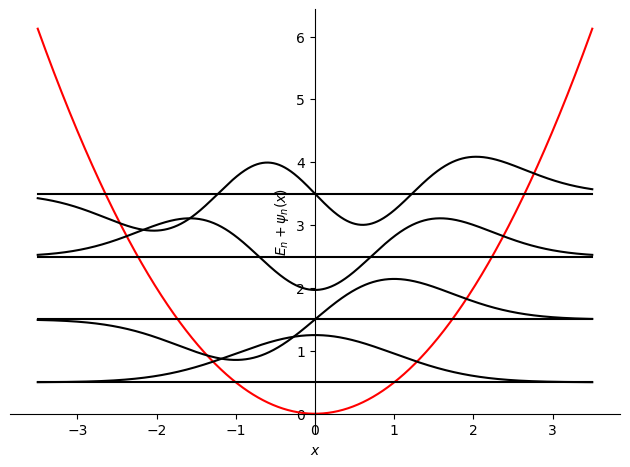

In [17]:
unit_parameters = {m: 1, ω: 1, ħ: 1}
x_limits = (x, -3.5, 3.5)

def plot_shifted(expression, n):
    shifted_expression = (
        n + sympy.Rational(1, 2) + expression.subs(unit_parameters)
    )
    return sympy.plot(
        shifted_expression, x_limits, show=False, line_color='black'
    )[0]

p = sympy.plot(
    x**2 / 2,
    x_limits,
    show=False,
    line_color='red',
    ylabel=r'$E_n + \psi_n(x)$',
)
for n, ψ in enumerate(states):
    p.append(plot_shifted(ψ, n))
    p.append(
        sympy.plot(
            n + sympy.Rational(1, 2),
            x_limits,
            show=False,
            line_color='black',
        )[0]
    )
p.show()

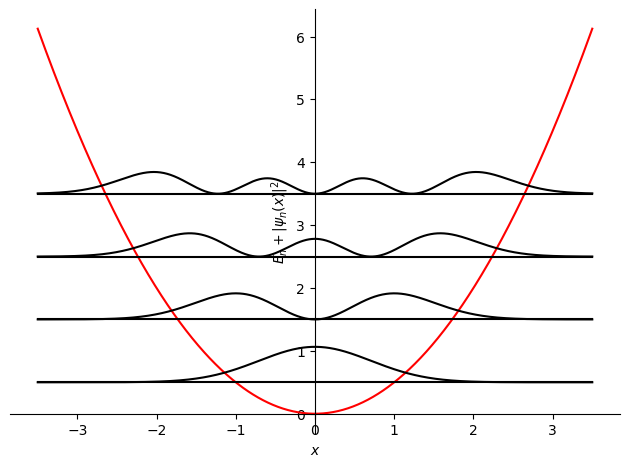

In [18]:
p = sympy.plot(
    x**2 / 2,
    x_limits,
    show=False,
    line_color='red',
    ylabel=r'$E_n + |\psi_n(x)|^2$',
)
for n, ψ in enumerate(states):
    p.append(plot_shifted(sympy.Abs(ψ) ** 2, n))
    p.append(
        sympy.plot(
            n + sympy.Rational(1, 2),
            x_limits,
            show=False,
            line_color='black',
        )[0]
    )
p.show()